# Assignment 6: Spatial Filtering (Averaging, Weighted and Gaussian)

**Objective:** Implement 2-D convolution by hand with three smoothing kernels - averaging, a weighted kernel (weights based on distance from the centre) and a Gaussian - using either zero or replicate padding.

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_image(size=128, seed=42):
    """Build a grayscale test image (gradient + shapes + texture) with NumPy and OpenCV."""
    rng = np.random.default_rng(seed)

    # Smooth horizontal gradient as the background
    canvas = np.tile(np.linspace(40, 140, size, dtype=np.float32), (size, 1))

    # Bright square, dark circle and a mid-grey diagonal line give us edges and flat regions
    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), 220, -1)
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, 30, -1)
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), 180, 3)

    # Light texture so the image is not perfectly smooth
    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

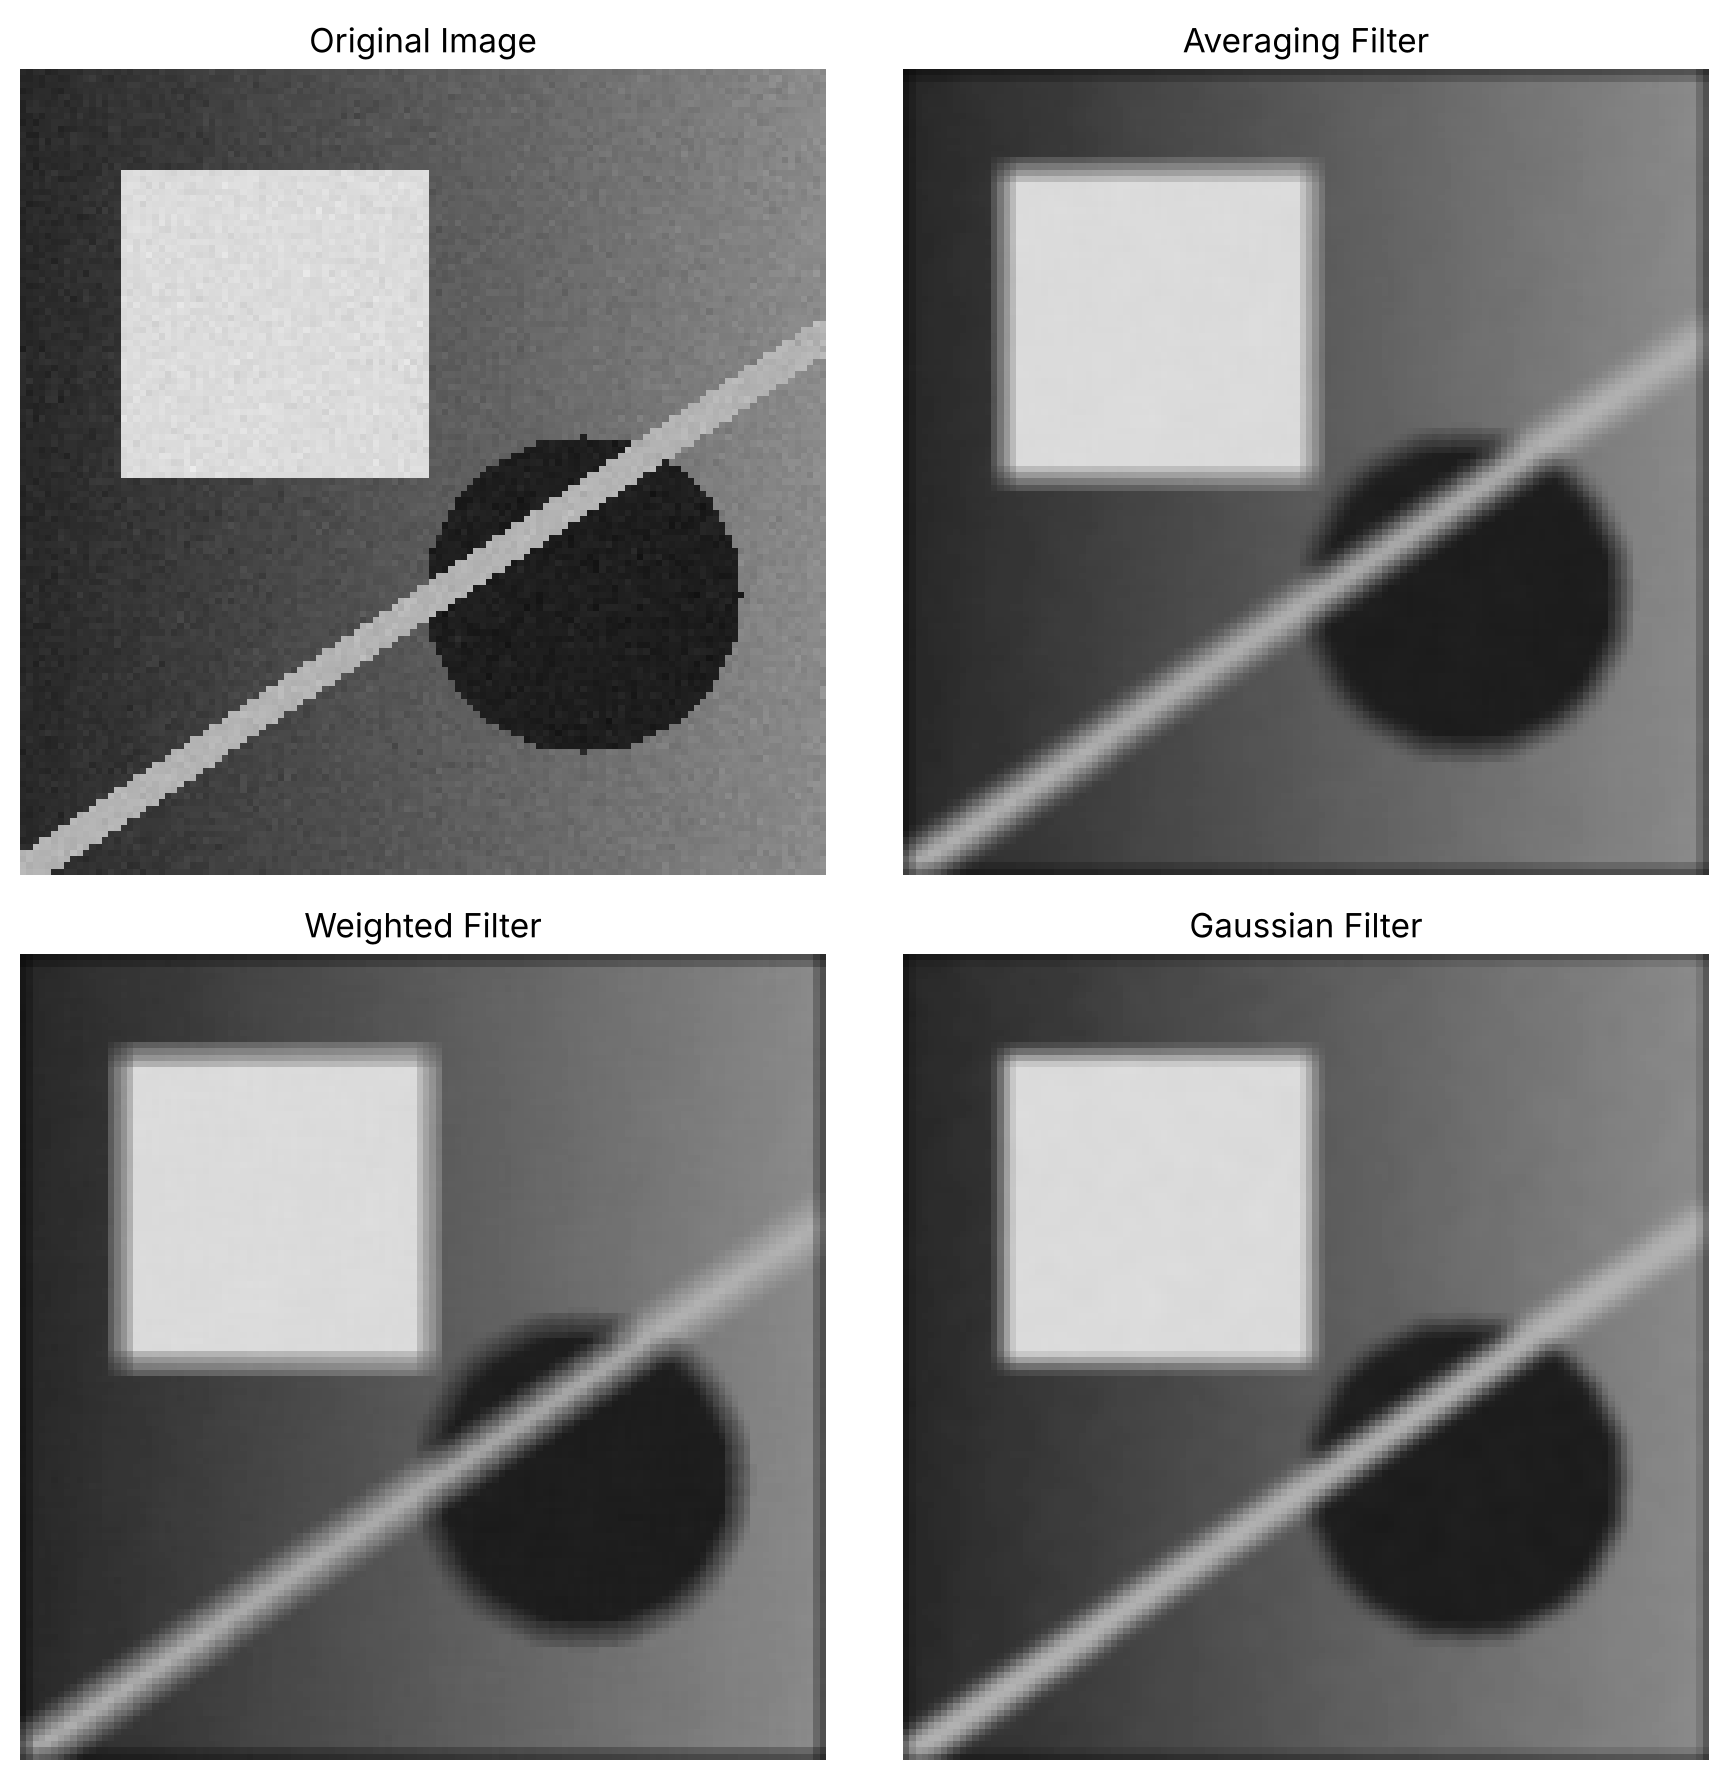

In [2]:
KERNEL_SIZE = 5            # odd number, e.g. 3 or 5
SIGMA = 1.5                # standard deviation for the Gaussian kernel
PADDING_METHOD = "zero"    # "zero" or "replicate"

grayscale_image = create_demo_image()
pad_size = KERNEL_SIZE // 2

# --- Padding -------------------------------------------------------------
if PADDING_METHOD == "zero":
    padded_image = cv2.copyMakeBorder(grayscale_image, pad_size, pad_size, pad_size, pad_size,
                                      cv2.BORDER_CONSTANT, value=0)
else:
    padded_image = cv2.copyMakeBorder(grayscale_image, pad_size, pad_size, pad_size, pad_size,
                                      cv2.BORDER_REPLICATE)

# --- Kernels -------------------------------------------------------------
averaging_kernel = np.ones((KERNEL_SIZE, KERNEL_SIZE), dtype=np.float32) / (KERNEL_SIZE * KERNEL_SIZE)

offsets = np.arange(-pad_size, pad_size + 1)
grid_x, grid_y = np.meshgrid(offsets, offsets)

# Weighted kernel: weight = Chebyshev distance from the centre, normalised to sum to 1
weighted_kernel = np.maximum(np.abs(grid_x), np.abs(grid_y)).astype(np.float32)
weighted_kernel = weighted_kernel / np.sum(weighted_kernel)

gaussian_kernel = np.exp(-(grid_x ** 2 + grid_y ** 2) / (2 * SIGMA ** 2))
gaussian_kernel = gaussian_kernel / np.sum(gaussian_kernel)


def apply_filter(padded, kernel, output_shape):
    """Slide the kernel over the padded image (correlation) and return a uint8 image."""
    height, width = output_shape
    filtered = np.zeros((height, width), dtype=np.float32)
    for row in range(height):
        for col in range(width):
            region = padded[row:row + KERNEL_SIZE, col:col + KERNEL_SIZE]
            filtered[row, col] = np.sum(region * kernel)
    return np.clip(filtered, 0, 255).astype(np.uint8)


averaged_image = apply_filter(padded_image, averaging_kernel, grayscale_image.shape)
weighted_image = apply_filter(padded_image, weighted_kernel, grayscale_image.shape)
gaussian_image = apply_filter(padded_image, gaussian_kernel, grayscale_image.shape)

show_images(
    [grayscale_image, averaged_image, weighted_image, gaussian_image],
    ["Original Image", "Averaging Filter", "Weighted Filter", "Gaussian Filter"],
    columns=2, figsize=(9, 9),
)